# 04 - PhoBERT và bảng kết quả gộp (bước 2.3, 2.4)
PhoBERT được fine-tune bằng `python -m src.train_phobert` (xem README); notebook này **chỉ đọc** xác suất đã lưu ở `results/preds/`
và `results/tables/*_cost.json`, rồi gộp mọi mô hình vào một bảng, quét ngưỡng và phân tích từng nhãn.
Mọi lựa chọn (cấu hình PhoBERT, ngưỡng) dựa trên **val**; test chỉ để báo cáo.

> **Cách đọc/chạy.** Notebook này chỉ **đọc** các kết quả đã lưu ở `results/preds/` và `results/tables/*_cost.json` rồi gộp, so sánh; chạy nhanh trên CPU. Muốn có thêm lần chạy PhoBERT, chạy `python -m src.train_phobert` (xem `README.md`) rồi chạy lại notebook này.
> Các lần chạy được đặt tên theo cấu hình, ví dụ `phobert_text_pw_sqrt_ep12` = emoji chuyển thành chữ (`text`), loss BCE có pos_weight căn bậc hai (`pw_sqrt`), tối đa 12 epoch (`ep12`). Ý nghĩa chỉ số xem đầu `02_tfidf_lr.ipynb`.

In [1]:
# Khởi tạo: tìm mọi lần chạy đã lưu xác suất (results/preds/*_val.npz) và nạp val/test.
# - P[(tên_lần_chạy, split)] = ma trận xác suất; Y[split] = nhãn thật.
# - assert kiểm tra thứ tự id khớp dữ liệu gốc (tránh lệch hàng).
# Notebook này KHÔNG huấn luyện: PhoBERT được train bằng `python -m src.train_phobert` (xem README).
import sys, glob, json, os
sys.path.insert(0, '..')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from src.data import *
from src.metrics import *

TAB, FIG, PRD = '../results/tables/', '../results/figures/', '../results/preds/'
data = load_all()
Ytr = label_matrix(data['train']); tiers = label_tiers(Ytr.sum(0))
runs = sorted({os.path.basename(f)[:-8] for f in glob.glob(PRD + '*_val.npz') if '_smoke' not in f})
print(runs)
P, Y = {}, {}
for r in runs:
    for s in ('val', 'test'):
        ids, y, p = load_preds(f'{PRD}{r}_{s}.npz')
        assert (ids == data[s].id.values).all(); P[(r, s)] = p; Y[s] = y

C:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


['bilstm', 'phobert_keep_bce', 'phobert_text_bce', 'phobert_text_bce_ep12', 'phobert_text_pw_sqrt', 'phobert_text_pw_sqrt_ep12', 'tfidf_lr']


## 1. Chi phí mô hình (bước 2.3)
`train_seconds` = tổng thời gian các epoch (gồm cả dự đoán val), **loại bỏ epoch bị máy ngủ** (epoch > 5 lần trung vị được thay bằng trung vị); `wall_seconds_raw` là số đo nguyên bản.

In [2]:
# Gộp chi phí mô hình vào model_cost.csv: số tham số, thời gian train, epoch tốt nhất/đã chạy, cấu hình, checkpoint (kèm mã revision), đỉnh bộ nhớ GPU.
# - train_seconds = tổng thời gian các epoch, nhưng epoch nào lâu hơn 5 lần trung vị (máy bị ngủ giữa chừng) thì thay bằng trung vị;
#   wall_seconds_raw giữ số đo gốc.
# - TF-IDF và BiLSTM đọc từ file kết quả của notebook 02/03.
cost = {}
for r in runs:
    f = f'{TAB}{r}_cost.json'
    if os.path.exists(f):
        c = json.load(open(f)); a = c['args']
        h = pd.read_csv(f'{TAB}{r}_history.csv').epoch_seconds
        adj = h.where(h <= 5 * h.median(), h.median())   # epoch bị máy ngủ (> 5x trung vị) thay bằng trung vị
        cost[r] = dict(n_params=c['n_params'], train_seconds=round(adj.sum(), 1), wall_seconds_raw=c['train_seconds'],
                       epochs=f"{c['best_epoch']}/{c['epochs_run']}",
                       config=f"emoji={a['emoji']}, loss={a['loss']}, lr={a['lr']}, bs={a['bs']}, max_len={a['max_len']}, seed={a['seed']}",
                       checkpoint=f"{c['checkpoint']}@{c['revision'][:8]}", peak_gpu_gb=c['peak_gpu_gb'])
for r, f in [('tfidf_lr', 'baseline_tfidf_lr.csv'), ('bilstm', 'baseline_bilstm.csv')]:
    b = pd.read_csv(TAB + f).iloc[0]
    cost[r] = dict(n_params=int(b.n_params), train_seconds=b.train_seconds, epochs='-', config=b.config, checkpoint='-', peak_gpu_gb=None)
cost = pd.DataFrame(cost).T; cost.index.name = 'run'
cost.to_csv(TAB + 'model_cost.csv'); cost

,n_params,train_seconds,wall_seconds_raw,epochs,config,checkpoint,peak_gpu_gb
run,,,,,,,
phobert_keep_bce,135019804,660.1,663.3,6/6,"emoji=keep, loss=bce, lr=2e-05, bs=16, max_len...",vinai/phobert-base@01daacda,3.26
phobert_text_bce,135019804,668.2,671.5,6/6,"emoji=text, loss=bce, lr=2e-05, bs=16, max_len...",vinai/phobert-base@01daacda,3.27
phobert_text_bce_ep12,135019804,1406.0,1412.1,12/12,"emoji=text, loss=bce, lr=2e-05, bs=16, max_len...",vinai/phobert-base@01daacda,3.27
phobert_text_pw_sqrt,135019804,674.5,677.6,6/6,"emoji=text, loss=pw_sqrt, lr=2e-05, bs=16, max...",vinai/phobert-base@01daacda,3.27
phobert_text_pw_sqrt_ep12,135019804,1232.2,6288.8,8/11,"emoji=text, loss=pw_sqrt, lr=2e-05, bs=16, max...",vinai/phobert-base@01daacda,3.27
tfidf_lr,1053556,2.7,NaN,-,"('word', 4, 'balanced')",-,None
bilstm,1377884,151.4,NaN,-,bce; emb200 hid128 drop0.3 lr1e-3 bs64 maxlen1...,-,None


## 2. Bảng kết quả gộp (ngưỡng 0.5)

In [3]:
# Bảng kết quả gộp: với mỗi lần chạy, tính chỉ số ở ngưỡng 0.5 trên val và test (Macro/Micro-F1, Hamming, LRAP, mAP, F1 theo nhóm tần suất)
# rồi nối với chi phí. Lưu ở baseline_results.csv (đầu vào của notebook 05).
rows = []
for r in runs:
    row = {'run': r}
    for s in ('val', 'test'):
        m = {**compute_metrics(Y[s], P[(r, s)]), **f1_by_tier(Y[s], P[(r, s)], tiers)}
        row.update({f'{s}_{k}': round(v, 4) for k, v in m.items()})
    rows.append(row)
res = pd.DataFrame(rows).set_index('run').join(cost[['n_params', 'train_seconds']])
cols = ['val_macro_f1', 'test_macro_f1', 'test_micro_f1', 'test_hamming_loss', 'test_lrap', 'test_mAP',
        'test_macro_f1_head', 'test_macro_f1_mid', 'test_macro_f1_tail', 'n_params', 'train_seconds']
res.to_csv(TAB + 'baseline_results.csv'); res[cols].sort_values('val_macro_f1', ascending=False)

,val_macro_f1,test_macro_f1,test_micro_f1,test_hamming_loss,test_lrap,test_mAP,test_macro_f1_head,test_macro_f1_mid,test_macro_f1_tail,n_params,train_seconds
run,,,,,,,,,,,
phobert_text_pw_sqrt_ep12,0.6030,0.6082,0.6240,0.0583,0.7530,0.6304,0.6345,0.6030,0.5817,135019804,1232.2
phobert_text_pw_sqrt,0.5950,0.5901,0.6050,0.0634,0.7423,0.6200,0.6178,0.6050,0.5371,135019804,674.5
phobert_text_bce_ep12,0.5847,0.5990,0.6247,0.0477,0.7564,0.6309,0.6406,0.5864,0.5627,135019804,1406.0
tfidf_lr,0.5338,0.5482,0.5630,0.0666,0.6936,0.5610,0.5773,0.5341,0.5295,1053556,2.7
bilstm,0.5164,0.5115,0.5408,0.0590,0.6753,0.5388,0.5518,0.5019,0.4732,1377884,151.4
phobert_text_bce,0.4957,0.5079,0.5753,0.0488,0.7339,0.5997,0.5956,0.4812,0.4316,135019804,668.2
phobert_keep_bce,0.4780,0.4909,0.5489,0.0513,0.7126,0.5850,0.5728,0.4540,0.4348,135019804,660.1


In [4]:
# Quy tắc chọn PhoBERT: lần chạy có val Macro-F1 (ngưỡng 0.5) cao nhất. Quy tắc đặt trước và chỉ dùng val.
ph = [r for r in runs if r.startswith('phobert')]
chosen = res.loc[ph, 'val_macro_f1'].idxmax()
print('Cấu hình PhoBERT được chọn (val Macro-F1 @0.5 cao nhất):', chosen)

Cấu hình PhoBERT được chọn (val Macro-F1 @0.5 cao nhất): phobert_text_pw_sqrt_ep12


## 3. Độ nhạy với ngưỡng (quét trên val)

,tau*_val,val@0.5,val@tau*,test@0.5,test@tau*,gain_test,gap_val_test@tau*
run,,,,,,,
tfidf_lr,0.525,0.5338,0.5357,0.5482,0.5508,0.0026,-0.0151
bilstm,0.350,0.5164,0.5184,0.5115,0.5163,0.0048,0.0021
phobert_keep_bce,0.225,0.4780,0.5548,0.4909,0.5622,0.0713,-0.0074
phobert_text_bce,0.225,0.4957,0.5745,0.5079,0.5729,0.0650,0.0016
phobert_text_bce_ep12,0.250,0.5847,0.6055,0.5990,0.6080,0.0090,-0.0025
phobert_text_pw_sqrt,0.625,0.5950,0.6009,0.5901,0.5969,0.0068,0.0040
phobert_text_pw_sqrt_ep12,0.575,0.6030,0.6077,0.6082,0.6125,0.0043,-0.0048


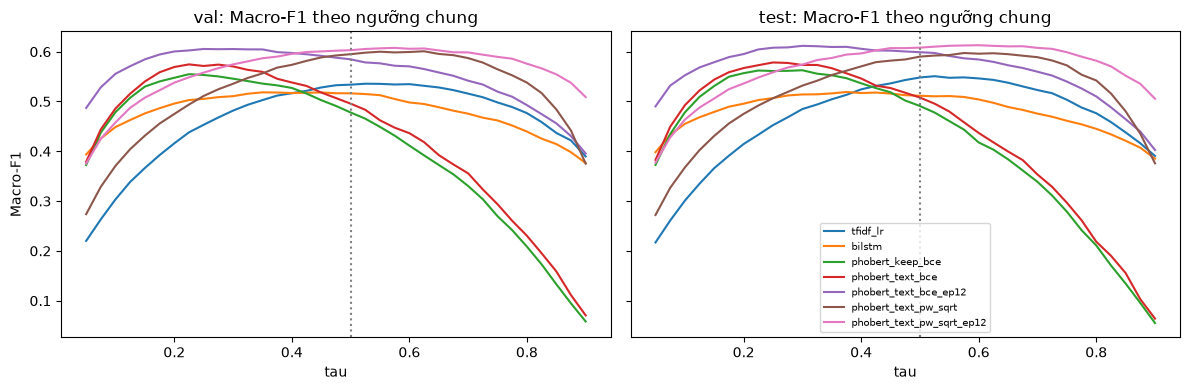

In [5]:
# Độ nhạy với MỘT ngưỡng chung tau (quét 0.05 - 0.90):
# - sw[run]: Macro-F1 trên val và test theo tau.
# - tau*_val: tau cho val Macro-F1 cao nhất (chọn trên val).
# - gain_test = test Macro-F1 tại tau* trừ test Macro-F1 tại 0.5 (chỉ báo cáo, không dùng để chọn).
# - gap_val_test@tau* = val F1 trừ test F1 tại tau*; chênh lớn gợi ý ngưỡng bị quá khớp val.
# Hình ở cell này gồm mọi lần chạy nên khá rối; hình gọn ở cell sau.
taus = np.round(np.arange(0.05, 0.91, 0.025), 3)
show = ['tfidf_lr', 'bilstm'] + ph
sw = {r: pd.DataFrame({'tau': taus,
        'val': [compute_metrics(Y['val'], P[(r, 'val')], t)['macro_f1'] for t in taus],
        'test': [compute_metrics(Y['test'], P[(r, 'test')], t)['macro_f1'] for t in taus]}) for r in show}
out = []
for r in show:
    d = sw[r]; tb = float(d.loc[d.val.idxmax(), 'tau'])
    out.append({'run': r, 'tau*_val': tb, 'val@0.5': round(compute_metrics(Y['val'], P[(r, 'val')])['macro_f1'], 4), 'val@tau*': round(d.val.max(), 4),
                'test@0.5': round(compute_metrics(Y['test'], P[(r, 'test')])['macro_f1'], 4), 'test@tau*': round(compute_metrics(Y['test'], P[(r, 'test')], tb)['macro_f1'], 4)})
thr = pd.DataFrame(out).set_index('run'); thr['gain_test'] = (thr['test@tau*'] - thr['test@0.5']).round(4)
thr['gap_val_test@tau*'] = (thr['val@tau*'] - thr['test@tau*']).round(4)
thr.to_csv(TAB + 'threshold_global_all_models.csv'); display(thr)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, s in zip(axes, ('val', 'test')):
    for r in show: ax.plot(sw[r].tau, sw[r][s], label=r)
    ax.axvline(0.5, ls=':', c='gray'); ax.set_title(f'{s}: Macro-F1 theo ngưỡng chung'); ax.set_xlabel('tau')
axes[0].set_ylabel('Macro-F1'); axes[1].legend(fontsize=7); plt.tight_layout(); plt.savefig(FIG + 'threshold_sweep_all_models.png'); plt.show()

### 3b. Hình gọn: 3 mô hình cuối cùng, đánh dấu tau* (chọn trên val)
Chấm tròn = tau* chọn trên val, đặt trên cả hai đồ thị; đường chấm xám = ngưỡng 0,5. Hình tổng hợp mọi lần chạy ở trên được giữ nguyên.

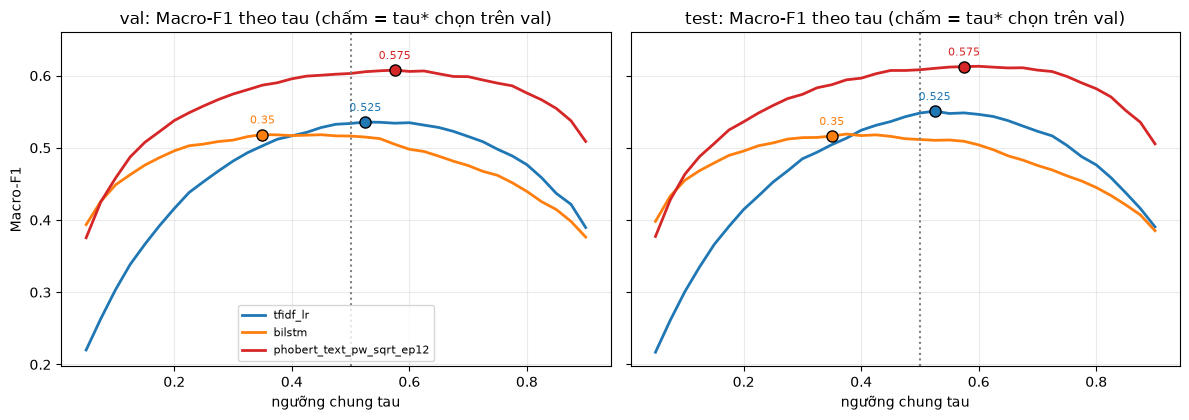

In [6]:
# Hình gọn: chỉ 3 mô hình cuối. Chấm tròn đánh dấu tau* (chọn trên val) trên cả hai đồ thị; đường chấm xám là 0.5.
# Hàm at(r, s, tau) lấy giá trị F1 tại điểm tau gần nhất trong lưới quét.
fin = ['tfidf_lr', 'bilstm', chosen]
col = dict(zip(fin, ['C0', 'C1', 'C3']))
def at(r, s, tau):
    d = sw[r]; return d.loc[(d.tau - tau).abs().idxmin(), s]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
for ax, s in zip(axes, ('val', 'test')):
    for r in fin:
        ax.plot(sw[r].tau, sw[r][s], c=col[r], lw=2, label=r)
        tb = thr.loc[r, 'tau*_val']; ax.plot([tb], [at(r, s, tb)], 'o', c=col[r], ms=8, mec='k')
        ax.annotate(f'{tb:g}', (tb, at(r, s, tb)), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=8, color=col[r])
    ax.axvline(0.5, ls=':', c='gray'); ax.set_xlabel('ngưỡng chung tau'); ax.grid(alpha=.25)
    ax.set_title(f'{s}: Macro-F1 theo tau (chấm = tau* chọn trên val)')
axes[0].set_ylabel('Macro-F1'); axes[0].legend(loc='lower center', fontsize=8); axes[0].set_ylim(top=0.66)
plt.tight_layout(); plt.savefig(FIG + 'threshold_sweep_final3.png'); plt.show()

### 3c. Hình so sánh 6 epoch với 12 epoch (test)
Cùng loss, chỉ khác số epoch: cho thấy độ nhạy với ngưỡng chung giảm mạnh khi mô hình hội tụ. Chấm tròn = tau* chọn trên val; số trong ngoặc là mức tăng Macro-F1 trên test so với ngưỡng 0,5.

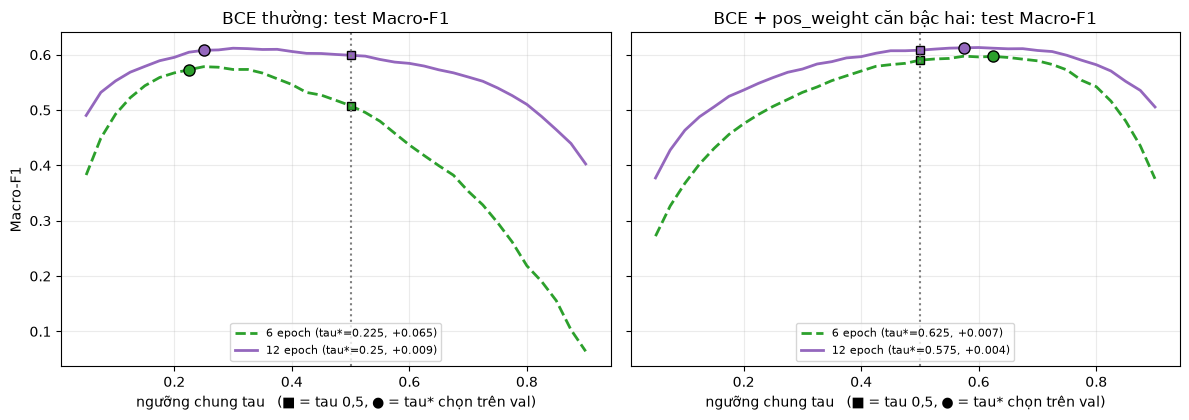

In [7]:
# So cùng một loss ở 6 epoch và 12 epoch (khác nhau về độ dài huấn luyện).
# Ô vuông = ngưỡng 0.5, chấm tròn = tau* chọn trên val; số trong chú giải là mức tăng Macro-F1 test khi đổi từ 0.5 sang tau*.
# Lưu ý: hai lần chạy cũng khác lịch giảm learning rate (phụ thuộc tổng số bước).
pairs = [('BCE thường', 'phobert_text_bce', 'phobert_text_bce_ep12'), ('BCE + pos_weight căn bậc hai', 'phobert_text_pw_sqrt', 'phobert_text_pw_sqrt_ep12')]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
for ax, (title, r6, r12) in zip(axes, pairs):
    for r, c, ls, lab in [(r6, 'C2', '--', '6 epoch'), (r12, 'C4', '-', '12 epoch')]:
        tb = thr.loc[r, 'tau*_val']; g = thr.loc[r, 'gain_test']
        ax.plot(sw[r].tau, sw[r].test, c=c, ls=ls, lw=2, label=f'{lab} (tau*={tb:g}, +{g:.3f})')
        ax.plot([tb], [at(r, 'test', tb)], 'o', c=c, ms=8, mec='k')
        ax.plot([0.5], [at(r, 'test', 0.5)], 's', c=c, ms=6, mec='k')
    ax.axvline(0.5, ls=':', c='gray'); ax.set_title(f'{title}: test Macro-F1'); ax.set_xlabel('ngưỡng chung tau   (■ = tau 0,5, ● = tau* chọn trên val)'); ax.grid(alpha=.25)
    ax.legend(loc='lower center', fontsize=8)
axes[0].set_ylabel('Macro-F1'); plt.tight_layout(); plt.savefig(FIG + 'threshold_sweep_6_vs_12_epoch.png'); plt.show()

## 4. F1 từng nhãn của PhoBERT được chọn (test, ngưỡng 0.5)

In [8]:
# F1/precision/recall/AP từng nhãn của PhoBERT được chọn. Spearman giữa F1 và số mẫu train cho biết F1 có phụ thuộc tần suất nhãn không.
# In thêm trung bình theo nhóm head/mid/tail.
pl = per_label_table(Y['test'], P[(chosen, 'test')], train_counts=Ytr.sum(0), tiers=tiers).round(4)
pl.to_csv(TAB + f'perlabel_{chosen}_test.csv')
rho, p = spearmanr(pl.f1, pl.train_count)
print(f'Spearman(F1, tần suất train) = {rho:.3f} (p = {p:.3f})')
print(pl.groupby('tier')[['f1', 'precision', 'recall']].mean().round(3))
pl.sort_values('f1', ascending=False)[['f1', 'precision', 'recall', 'ap', 'support', 'train_count', 'tier']]

Spearman(F1, tần suất train) = 0.195 (p = 0.320)
         f1  precision  recall
tier                          
head  0.635      0.560   0.737
mid   0.603      0.557   0.670
tail  0.582      0.525   0.664


,f1,precision,recall,ap,support,train_count,tier
embarrassment,0.8210,0.7705,0.8785,0.9209,107,885,mid
gratitude,0.8170,0.7559,0.8889,0.8906,108,765,mid
amusement,0.7793,0.7375,0.8262,0.8209,374,2868,head
optimism,0.7284,0.6484,0.8310,0.8187,142,1046,head
sadness,0.7258,0.6603,0.8058,0.7777,345,2785,head
pride,0.7250,0.7838,0.6744,0.7452,86,774,mid
remorse,0.7135,0.6735,0.7586,0.7013,87,707,tail
fear,0.6667,0.6415,0.6939,0.6876,98,745,tail
love,0.6573,0.5493,0.8182,0.7400,143,1175,head
curiosity,0.6522,0.5769,0.7500,0.6247,100,840,mid


In [9]:
# Cột phobert_minus_tfidf > 0 nghĩa là PhoBERT có F1 cao hơn TF-IDF ở nhãn đó.
# So F1 từng nhãn giữa 3 mô hình (test, ngưỡng 0.5)
cmp = pd.DataFrame({r: per_label_f1(Y['test'], binarize(P[(r, 'test')])) for r in ['tfidf_lr', 'bilstm', chosen]}, index=LABELS).round(3)
cmp['phobert_minus_tfidf'] = (cmp[chosen] - cmp['tfidf_lr']).round(3)
cmp.to_csv(TAB + 'perlabel_compare_3models_test.csv'); cmp.sort_values('phobert_minus_tfidf')

,tfidf_lr,bilstm,phobert_text_pw_sqrt_ep12,phobert_minus_tfidf
fear,0.714,0.633,0.667,-0.047
grief,0.612,0.615,0.584,-0.028
gratitude,0.839,0.806,0.817,-0.022
love,0.662,0.669,0.657,-0.005
anger,0.593,0.544,0.598,0.005
confusion,0.444,0.365,0.469,0.025
caring,0.576,0.556,0.612,0.036
remorse,0.677,0.642,0.714,0.037
desire,0.396,0.407,0.441,0.045
admiration,0.536,0.486,0.581,0.045
